<a href="https://colab.research.google.com/github/yulianacm/Investigacion-de-operaciones/blob/main/Ejercicios_T5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TAREA 5 - <font color ="pink"> **CADENAS ABSORVENTES**

En esta notebook resolvemos los dos ejercicios de la Tarea 5 de dos maneras:

1. Por simulación
2. Forma analítica

Primero insertamos las librerías:

In [ ]:
import random
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

# <font color="SkyBlue"> Ejercicio 1</font>

Se coloca una rata blanca en el laberinto que se muestra.

En ausencia de aprendizaje, cabría suponer que la rata se desplaza por el laberinto
de forma aleatoria; es decir, si existen *k* posibles salidas desde un compartimento, la rata elige cada una de ellas con probabilidad *1/k*. En cada unidad de tiempo, la rata se traslada a un compartimento adyacente. Sea $*X_n*$ el compartimento ocupado en el
instante *n*. El compartimento 7 contiene comida y en el 8 hay un mecanismo de descargas eléctricas. ¿Cuál es la probabilidad de que la rata, al moverse aleatoriamente,
encuentre la comida antes de recibir una descarga?

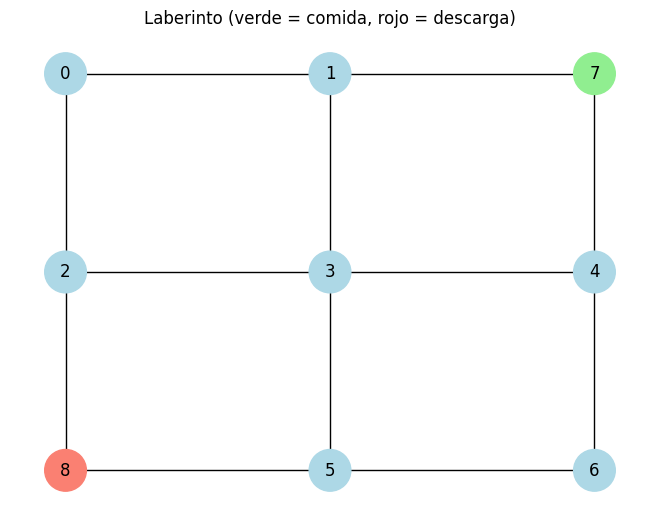

In [ ]:
G = nx.Graph()
puertas = [(0, 1), (0, 2), (1, 3), (1, 7),
 (2, 3), (2, 8), (3, 4), (3, 5),
  (4, 6), (4, 7), (5, 6), (5, 8)]

G.add_edges_from(puertas)
# Dibujo del laberinto
lugar = {0: (0, 2), 1: (1, 2), 7: (2, 2),
         2: (0, 1), 3: (1, 1), 4: (2, 1),
         8: (0, 0), 5: (1, 0), 6: (2, 0)}

colores = ["lightgreen" if n == 7 else "salmon" if n == 8 else "lightblue" for n in G.nodes]

nx.draw(G, lugar, with_labels=True, node_color=colores, node_size=900)
plt.title("Laberinto (verde = comida, rojo = descarga)")
plt.show()

#mueve a la rata al azar hasta que llega al 7 o al 8,
#y regresa en cuál terminó.

def mover_rata():
  lugar_actual = 0   # empieza en el 0
  while lugar_actual != 7 and lugar_actual != 8:
    vecinos = list(G.neighbors(lugar_actual))      # puertas disponibles
    lugar_actual = random.choice(vecinos)          # escoge una al azar
  return lugar_actual

Repetimos el experimento 100000 veces y contamos cuántas veces llegó a la comida.

In [ ]:
repeticiones = 100000
veces_comida = 0
for i in range(repeticiones):
  if mover_rata() == 7:
    veces_comida += 1

prob_simulada = veces_comida / repeticiones
print("Probabilidad de llegar a la comida:", prob_simulada)

print("== Comparación ==")
print("Simulación:", prob_simulada)
print("Analítica: 1/2 = 0.5")

Probabilidad de llegar a la comida: 0.50049
== Comparación ==
Simulación: 0.50049
Analítica: 1/2 = 0.5


### <font color="SkyBlue"> Conclusión</font>
La probabilidad de que la rata encuentre la comida antes de la descarga es $\frac{1}{2}$. La simulación da casi lo mismo que la solución analítica (hecha a mano en tarea 5), y entre más repeticiones hacemos, más se acerca.

# <font color="Fuchsia"> Ejercicio 2</font>

Si el juego comienza en la casilla 1 y termina al alcanzar la casilla 20 (sin retorno), para el tablero mostrado y un dado ordinario.

¿Cuál es el número esperado de tiradas para terminar un juego solitario?

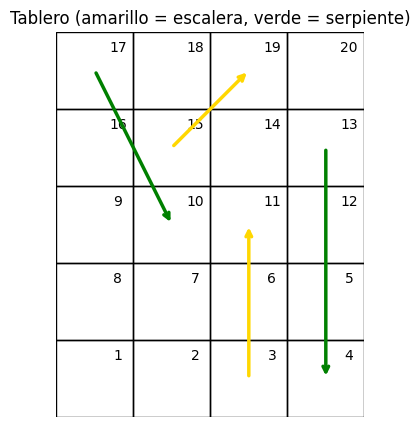

In [ ]:
# Agregamos el grafo
T = nx.DiGraph()
T.add_edges_from([(3, 11), (15, 19),    # escaleras
                  (17, 10), (13, 4)])    # serpientes

def centro(casilla):
  fila = (casilla - 1) // 4
  col = (casilla - 1) % 4
  if fila % 2 == 1:          # las filas de en medio van de derecha a izquierda
    col = 3 - col
  return col + 0.5, fila + 0.5;

fig, ax = plt.subplots(figsize=(4, 5))
for c in range(1, 21):
  x, y = centro(c)
  ax.add_patch(plt.Rectangle((x - 0.5, y - 0.5), 1, 1, fill=False))
  ax.text(x + 0.3, y + 0.3, str(c), ha="center", va="center")

for inicio, fin in T.edges():
  color = "gold" if fin > inicio else "green"
  ax.annotate("", xy=centro(fin), xytext=centro(inicio),
              arrowprops=dict(arrowstyle="->",
                              color=color, lw=2.5))

ax.set_xlim(0, 4); ax.set_ylim(0, 5);
ax.set_aspect("equal"); ax.axis("off")
plt.title("Tablero (amarillo = escalera, verde = serpiente)")
plt.show()

In [ ]:
def mover_ficha(casilla, dado): # Marca a la casilla que llega según el dado. Si cae en escalera o serpiente, manda hasta su destino.
  nueva = casilla + dado
  if nueva >= 20:                          # sin retorno
    return 20
  if T.has_node(nueva) and T.out_degree(nueva) > 0:
    nueva = list(T.successors(nueva))[0]  # escalera o serpiente
  return nueva

def jugar(): #tira el dado hasta llegar a la 20
  casilla = 1
  tiradas = 0
  while casilla != 20:
    dado = random.randint(1, 6)
    tiradas += 1
    casilla = mover_ficha(casilla, dado)
  return tiradas


Jugamos 100000 partidas y sacamos el promedio de tiradas.


In [22]:
partidas = 100000
total = 0
for i in range(partidas):
  total += jugar()

promedio_simulado = total / partidas
print("Promedio de tiradas:", promedio_simulado)

print("== Comparación ==")
print("Simulación:", round(promedio_simulado, 2), "tiradas")
print("Analítica: mínimo 6, esperadas 11.56")

Promedio de tiradas: 6.91034
== Comparación ==
Simulación: 6.91 tiradas
Analítica: mínimo 6, esperadas 11.56
